# Домашнее задание 2 (CNN)

Сделайте обучение сверточной нейронной сети на выбранном датасете:
- Создайте свой класс SimpleCNN с помощью PyTorch и обучите его
- Используйте предобученную сеть (например, ResNet).

Сравните полученные результаты и постройте визуализацию (графики, изображения и т д - см пример).

In [ ]:
%pip install kagglehub --quiet

## Загрузка датасета

In [ ]:
import kagglehub

path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Path to dataset files: /kaggle/input/brain-tumor-mri-dataset


In [ ]:
import os, time, copy, random
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import torchvision.models as models

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    precision_recall_fscore_support
)

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| Torch:", torch.__version__)

Device: cpu | Torch: 2.11.0+cpu


## Входные данные

In [ ]:
IMG_SIZE = 128 # размер исходных изображений варьируется, сожмем до 128x128
TRAIN_DIR = os.path.join(path, "Training")
TEST_DIR  = os.path.join(path, "Testing")

classes = sorted(os.listdir(TRAIN_DIR))
print("Классы:", classes)

Классы: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
def load_folder(root):
    images, labels = [], []
    for cls in classes:
        cls_path = os.path.join(root, cls)
        if not os.path.isdir(cls_path):
            continue
        files = sorted(os.listdir(cls_path))
        for name in files:
            try:
                img = Image.open(os.path.join(cls_path, name)).convert("RGB")
                img = img.resize((IMG_SIZE, IMG_SIZE))
            except Exception as e:
                print("skip", name, e); continue
            images.append(np.array(img))
            labels.append(cls)
    return np.array(images, dtype=np.uint8), np.array(labels)

X_train_all, y_train_all = load_folder(TRAIN_DIR)
X_test, y_test = load_folder(TEST_DIR)

print("Train pool:", X_train_all.shape, "Test:", X_test.shape)

Train pool: (5600, 128, 128, 3) Test: (1600, 128, 128, 3)


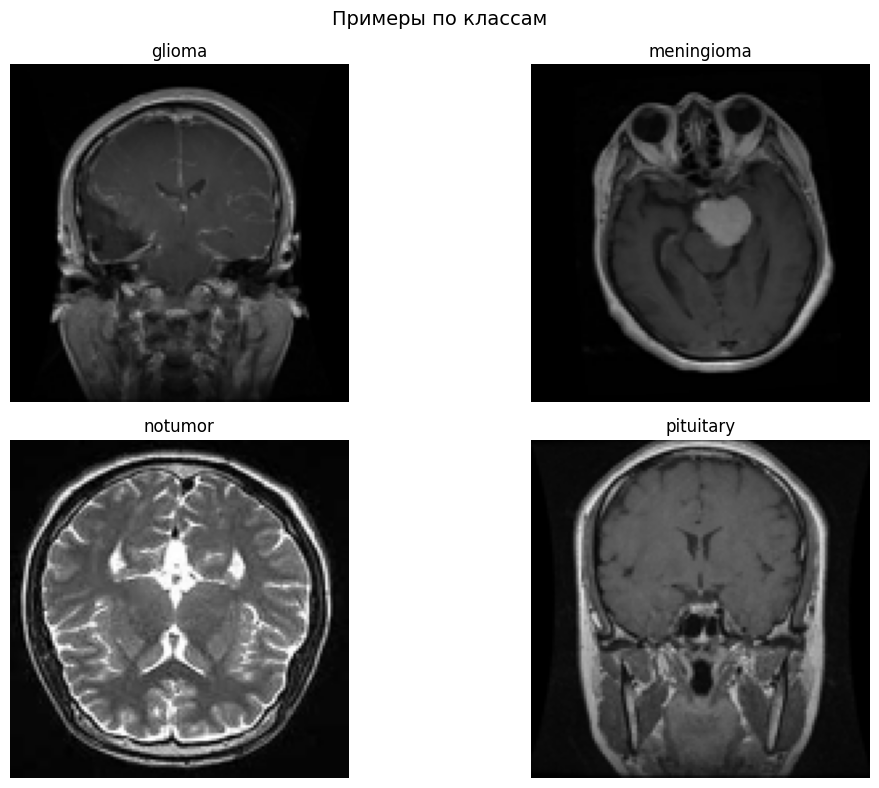

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, cls in zip(axes.ravel(), classes):
    idx = np.where(y_train_all == cls)[0][0]
    ax.imshow(X_train_all[idx])
    ax.set_title(cls)
    ax.axis("off")
plt.suptitle("Примеры по классам", fontsize=14)
plt.tight_layout(); plt.show()

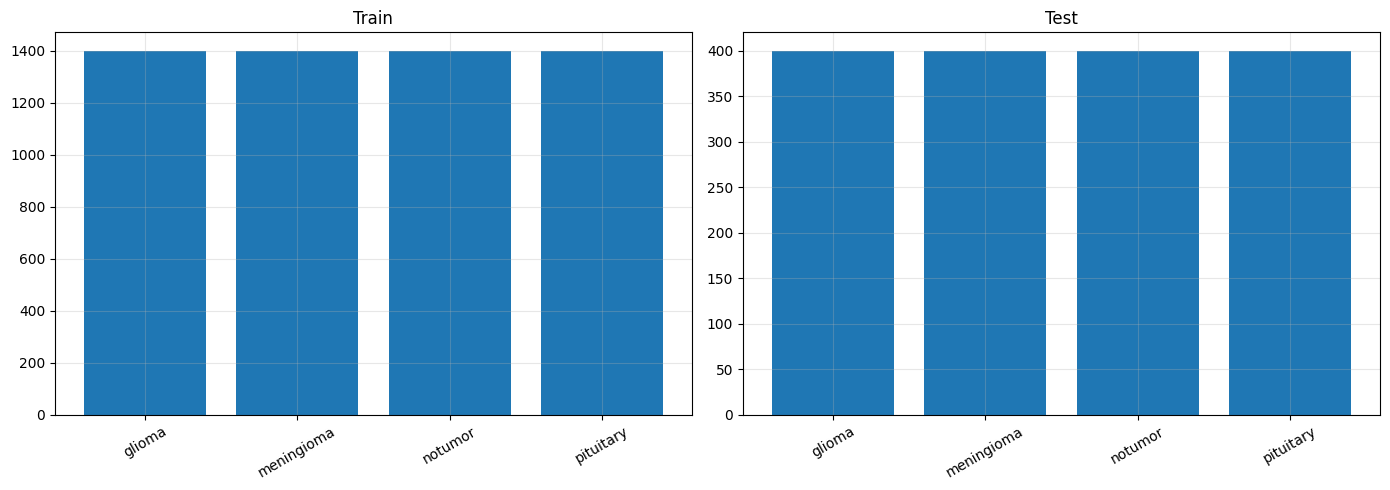

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (y_, ttl) in zip(axes, [(y_train_all, "Train"), (y_test, "Test")]):
    u, c = np.unique(y_, return_counts=True)
    ax.bar(u, c); ax.set_title(ttl); ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [ ]:
le = LabelEncoder()
le.fit(classes)
class_names = list(le.classes_)
print("Классы:", class_names)

y_train_all_enc = le.transform(y_train_all)
y_test_enc = le.transform(y_test)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_all, y_train_all_enc,
    test_size=0.2, random_state=SEED, stratify=y_train_all_enc
)
print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Классы: [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]
Train: 4480, Val: 1120, Test: 1600


In [ ]:
# Нормализация по train
X_train_f = X_train.astype(np.float32) / 255.0
mean = X_train_f.mean(axis=(0, 1, 2)).astype(np.float32)
std  = X_train_f.std(axis=(0, 1, 2)).astype(np.float32)
print("mean:", mean, "std:", std)

train_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

eval_tfms = T.Compose([
    T.ToPILImage(),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=mean, std=std),
])

mean: [0.14160526 0.14160527 0.14164548] std: [0.17598583 0.17598517 0.17602508]


In [ ]:
class ImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = int(self.labels[idx])
        if self.transform:
            img = self.transform(img)
        return img, label

BATCH_SIZE = 64
train_loader = DataLoader(ImageDataset(X_train, y_train, train_tfms),
                          batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(ImageDataset(X_val,   y_val,   eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(ImageDataset(X_test,  y_test_enc, eval_tfms),
                          batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

## Simple CNN и функция обучения

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes = 4):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1   = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2   = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3   = nn.BatchNorm2d(128)

        self.conv4 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.bn4   = nn.BatchNorm2d(128)

        self.pool    = nn.MaxPool2d(2, 2)
        self.relu    = nn.ReLU(inplace=True)
        self.dropout = nn.Dropout(0.5)

        self.fc1 = nn.Linear(128 * (IMG_SIZE // 16) * (IMG_SIZE // 16), 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward(); optimizer.step()
        running_loss += loss.item() * xb.size(0)
        correct += (out.argmax(1) == yb).sum().item()
        total += xb.size(0)
    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    y_true, y_pred = [], []
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        out = model(xb)
        loss = criterion(out, yb)
        running_loss += loss.item() * xb.size(0)
        pred = out.argmax(1)
        correct += (pred == yb).sum().item()
        total += xb.size(0)
        y_true.extend(yb.cpu().numpy())
        y_pred.extend(pred.cpu().numpy())
    return (running_loss / total, correct / total,
            np.array(y_true), np.array(y_pred))

def fit(model, train_loader, val_loader, epochs=15, lr=1e-3,
        weight_decay=0.0, patience=5, title="Model"):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr, weight_decay=weight_decay
    )
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )
    history = {"train_loss": [], "val_loss": [],
               "train_acc": [],  "val_acc": [], "time": []}
    best_val_loss, best_state, no_improve = float("inf"), None, 0

    for epoch in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(va_loss)
        dt = time.time() - t0

        for k, v in zip(["train_loss","val_loss","train_acc","val_acc","time"],
                        [tr_loss, va_loss, tr_acc, va_acc, dt]):
            history[k].append(v)

        print(f"[{title}] Ep {epoch+1:02d}/{epochs} | "
              f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
              f"lr {optimizer.param_groups[0]['lr']:.2e} | {dt:.1f}s")

        if va_loss < best_val_loss - 1e-4:
            best_val_loss = va_loss
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
        else:
            no_improve += 1
            if no_improve >= patience:
                print(f"Early stopping on epoch {epoch+1}")
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return history

In [ ]:
cnn_model = SimpleCNN(num_classes=4).to(device)
hist_cnn = fit(cnn_model, train_loader, val_loader,
               epochs=15, lr=1e-3, weight_decay=1e-5,
               patience=4, title="SimpleCNN")

[SimpleCNN] Ep 01/15 | train loss 1.1722 acc 0.5978 | val loss 0.6690 acc 0.7536 | lr 1.00e-03 | 285.7s
[SimpleCNN] Ep 02/15 | train loss 0.6340 acc 0.7504 | val loss 0.5642 acc 0.7768 | lr 1.00e-03 | 276.2s
[SimpleCNN] Ep 03/15 | train loss 0.5507 acc 0.7801 | val loss 0.4658 acc 0.8125 | lr 1.00e-03 | 272.3s
[SimpleCNN] Ep 04/15 | train loss 0.4809 acc 0.8109 | val loss 0.4374 acc 0.8107 | lr 1.00e-03 | 268.8s
[SimpleCNN] Ep 05/15 | train loss 0.4260 acc 0.8364 | val loss 0.4116 acc 0.8125 | lr 1.00e-03 | 272.1s
[SimpleCNN] Ep 06/15 | train loss 0.3768 acc 0.8545 | val loss 0.4469 acc 0.8562 | lr 1.00e-03 | 268.2s
[SimpleCNN] Ep 07/15 | train loss 0.3798 acc 0.8547 | val loss 0.4064 acc 0.8509 | lr 1.00e-03 | 268.7s
[SimpleCNN] Ep 08/15 | train loss 0.3403 acc 0.8641 | val loss 0.2828 acc 0.8955 | lr 1.00e-03 | 271.4s
[SimpleCNN] Ep 09/15 | train loss 0.3033 acc 0.8846 | val loss 0.2805 acc 0.9054 | lr 1.00e-03 | 270.5s
[SimpleCNN] Ep 10/15 | train loss 0.2997 acc 0.8915 | val loss 0

## ResNet

In [ ]:
def build_resnet18(num_classes=4, freeze_backbone=False):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

resnet_model = build_resnet18(num_classes=4, freeze_backbone=False).to(device)
hist_resnet = fit(resnet_model, train_loader, val_loader,
                  epochs=10, lr=3e-4, weight_decay=1e-4,
                  patience=3, title="ResNet18")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 122MB/s]


[ResNet18] Ep 01/10 | train loss 0.3161 acc 0.8830 | val loss 0.1484 acc 0.9384 | lr 3.00e-04 | 413.9s
[ResNet18] Ep 02/10 | train loss 0.1151 acc 0.9600 | val loss 0.1581 acc 0.9482 | lr 3.00e-04 | 416.2s
[ResNet18] Ep 03/10 | train loss 0.0858 acc 0.9692 | val loss 0.1491 acc 0.9464 | lr 3.00e-04 | 412.4s
[ResNet18] Ep 04/10 | train loss 0.0626 acc 0.9786 | val loss 0.1397 acc 0.9527 | lr 3.00e-04 | 411.4s
[ResNet18] Ep 05/10 | train loss 0.0433 acc 0.9848 | val loss 0.2565 acc 0.9313 | lr 3.00e-04 | 411.4s
[ResNet18] Ep 06/10 | train loss 0.0563 acc 0.9812 | val loss 0.0849 acc 0.9723 | lr 3.00e-04 | 417.6s
[ResNet18] Ep 07/10 | train loss 0.0338 acc 0.9879 | val loss 0.1174 acc 0.9554 | lr 3.00e-04 | 411.7s
[ResNet18] Ep 08/10 | train loss 0.0252 acc 0.9917 | val loss 0.0806 acc 0.9750 | lr 3.00e-04 | 409.3s
[ResNet18] Ep 09/10 | train loss 0.0217 acc 0.9933 | val loss 0.0771 acc 0.9786 | lr 3.00e-04 | 417.2s
[ResNet18] Ep 10/10 | train loss 0.0339 acc 0.9877 | val loss 0.0605 acc 

## Визуализация результатов

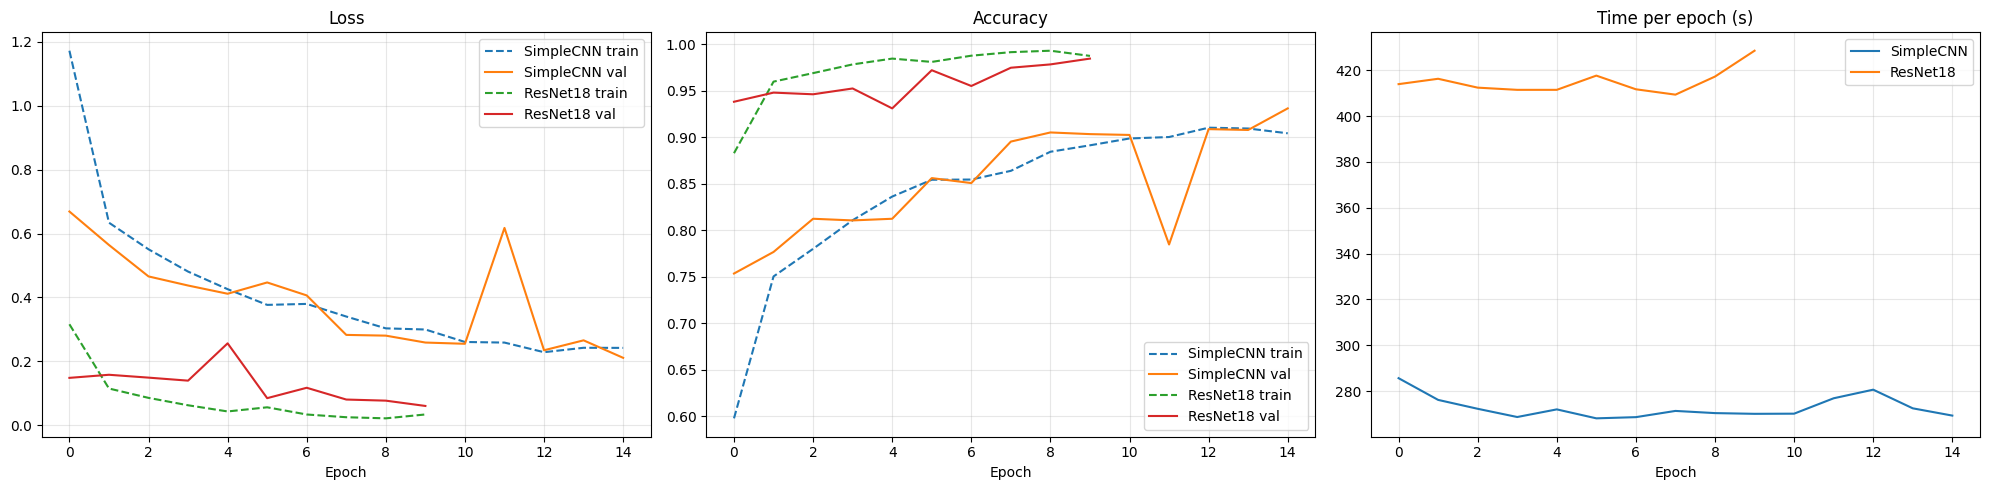

In [ ]:
def plot_histories(histories):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    for name, h in histories.items():
        axes[0].plot(h["train_loss"], "--", label=f"{name} train")
        axes[0].plot(h["val_loss"],   "-",  label=f"{name} val")
        axes[1].plot(h["train_acc"],  "--", label=f"{name} train")
        axes[1].plot(h["val_acc"],    "-",  label=f"{name} val")
        axes[2].plot(h["time"],       "-",  label=f"{name}")
    axes[0].set_title("Loss");     axes[0].set_xlabel("Epoch"); axes[0].grid(alpha=0.3)
    axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].grid(alpha=0.3)
    axes[2].set_title("Time per epoch (s)"); axes[2].set_xlabel("Epoch"); axes[2].grid(alpha=0.3)
    for ax in axes: ax.legend()
    plt.tight_layout(); plt.show()

plot_histories({"SimpleCNN": hist_cnn, "ResNet18": hist_resnet})


SimpleCNN — Test Accuracy: 0.8612
              precision    recall  f1-score   support

      glioma     0.9639    0.6675    0.7888       400
  meningioma     0.7820    0.8250    0.8029       400
     notumor     0.7893    0.9925    0.8793       400
   pituitary     0.9648    0.9600    0.9624       400

    accuracy                         0.8612      1600
   macro avg     0.8750    0.8612    0.8583      1600
weighted avg     0.8750    0.8612    0.8583      1600



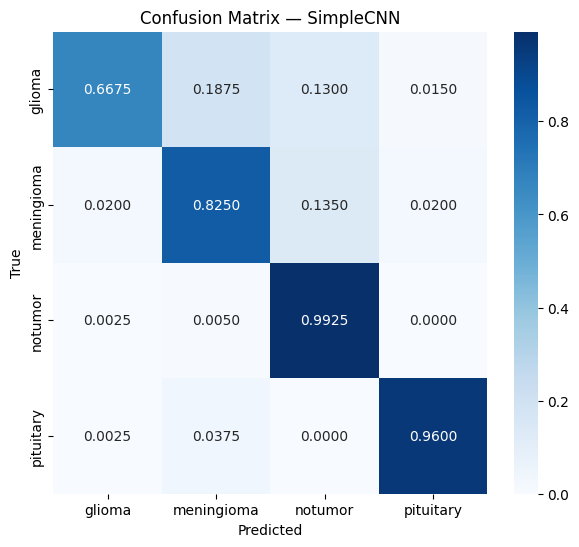


ResNet18 — Test Accuracy: 0.9425
              precision    recall  f1-score   support

      glioma     0.9938    0.7975    0.8849       400
  meningioma     0.8731    0.9800    0.9234       400
     notumor     0.9454    0.9950    0.9695       400
   pituitary     0.9756    0.9975    0.9864       400

    accuracy                         0.9425      1600
   macro avg     0.9469    0.9425    0.9411      1600
weighted avg     0.9469    0.9425    0.9411      1600



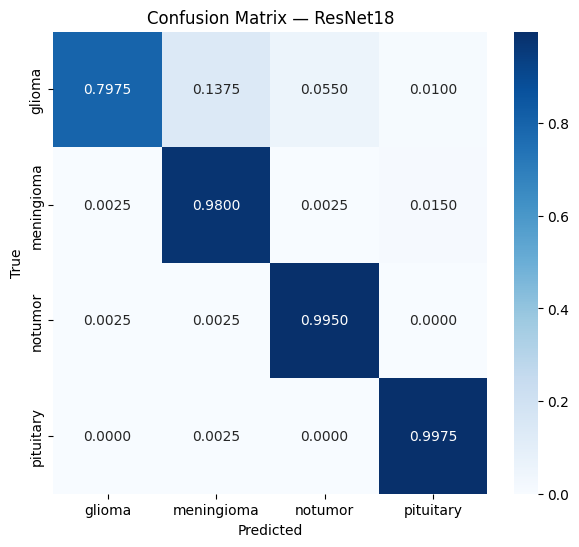

In [ ]:
def full_report(model, loader, title):
    criterion = nn.CrossEntropyLoss()
    _, acc, y_true, y_pred = evaluate(model, loader, criterion)
    print(f"\n{'='*60}\n{title} — Test Accuracy: {acc:.4f}\n{'='*60}")
    print(classification_report(y_true, y_pred,
                                target_names=class_names, digits=4))
    cm = confusion_matrix(y_true, y_pred, normalize = 'true')
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt=".4f", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted"); plt.ylabel("True")
    plt.title(f"Confusion Matrix — {title}")
    plt.show()
    return {"acc": acc, "y_true": y_true, "y_pred": y_pred}

res_cnn    = full_report(cnn_model,    test_loader, "SimpleCNN")
res_resnet = full_report(resnet_model, test_loader, "ResNet18")

In [ ]:
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

def summarize(name, hist, res, model):
    p, r, f, _ = precision_recall_fscore_support(
        res["y_true"], res["y_pred"], average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Params": f"{count_params(model):,}",
        "Best val acc": f"{max(hist['val_acc']):.4f}",
        "Test acc":     f"{res['acc']:.4f}",
        "Macro precision": f"{p:.4f}",
        "Macro recall":    f"{r:.4f}",
        "Macro F1":        f"{f:.4f}",
        "Mean epoch time (s)": f"{np.mean(hist['time']):.1f}",
        "Epochs trained": len(hist["time"]),
    }

df_cmp = pd.DataFrame([
    summarize("SimpleCNN", hist_cnn,    res_cnn,    cnn_model),
    summarize("ResNet18",  hist_resnet, res_resnet, resnet_model),
]).set_index("Model")
df_cmp

,Params,Best val acc,Test acc,Macro precision,Macro recall,Macro F1,Mean epoch time (s),Epochs trained
Model,,,,,,,,
SimpleCNN,"2,339,972",0.9313,0.8612,0.8750,0.8612,0.8583,272.9,15
ResNet18,"11,178,564",0.9848,0.9425,0.9469,0.9425,0.9411,415.0,10


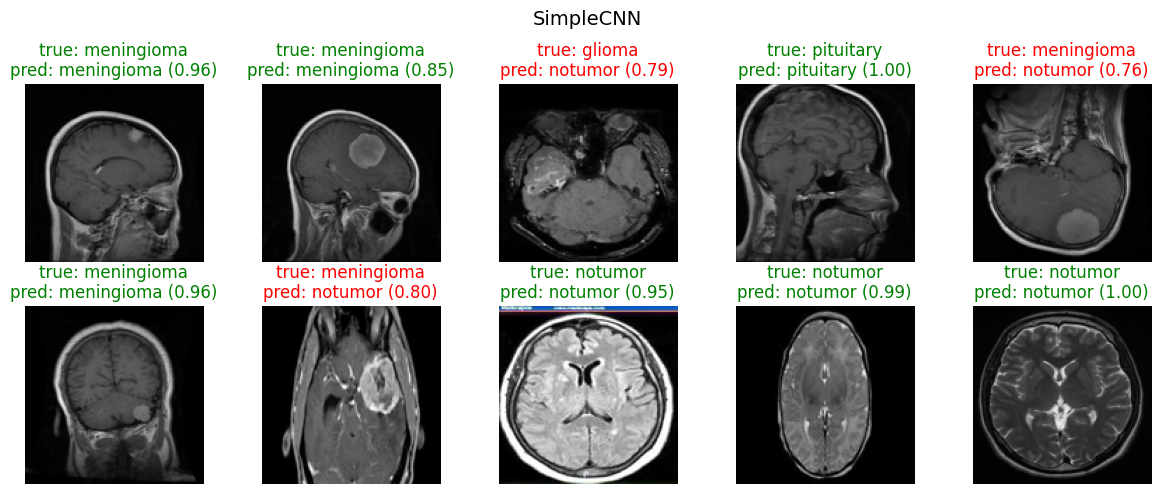

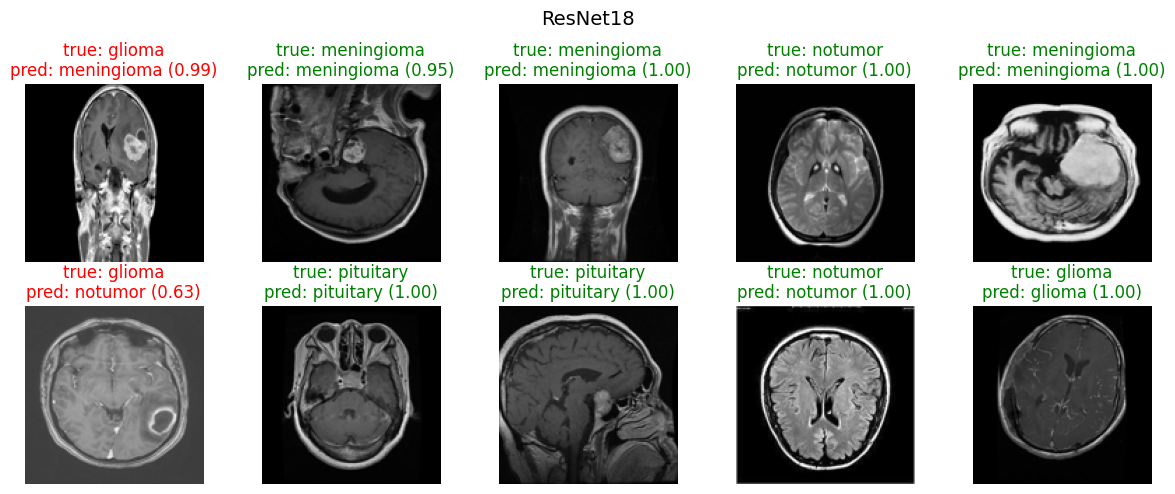

In [ ]:
@torch.no_grad()
def show_predictions(model, images, labels, n=10, title="Model"):
    model.eval()
    idxs = np.random.choice(len(images), n, replace=False)
    fig, axes = plt.subplots(2, n // 2, figsize=(12, 5))
    for ax, i in zip(axes.ravel(), idxs):
        tensor = eval_tfms(images[i]).unsqueeze(0).to(device)
        prob = torch.softmax(model(tensor), dim=1).cpu().numpy().ravel()
        pred = int(np.argmax(prob))
        ax.imshow(images[i])
        color = "green" if pred == labels[i] else "red"
        ax.set_title(f"true: {class_names[labels[i]]}\n"
                     f"pred: {class_names[pred]} ({prob[pred]:.2f})",
                     color=color)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout(); plt.show()

show_predictions(cnn_model,    X_test, y_test_enc, n=10, title="SimpleCNN")
show_predictions(resnet_model, X_test, y_test_enc, n=10, title="ResNet18")